# Project 2 — Rebuild the Palmer Solubility Paper (ALL STAGES)
**Masood Ur Rehman** · ESOL dataset (1,128 molecules) · RDKit + scikit-learn · Google Colab

Run the cells from top to bottom, one by one with **Shift + Enter**. Each stage builds on the one before it.

# Project 2 — Stage 1: Load the ESOL Solubility Data
**Goal of this stage:** get the data into Python and look at it. Nothing more.

This is the same kind of data Palmer et al. (2007) used for their solubility paper, the one you reviewed. Run each cell one by one with **Shift + Enter**.

In [1]:
# Step 1: Install RDKit. RDKit is the chemistry tool for Python.
# This takes about a minute. It is normal to see a lot of text.
!pip install rdkit -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 29.2 MB/s eta 0:00:00


In [2]:
# Step 2: Import pandas (Python's table tool).
import pandas as pd

In [3]:
# Step 3: Load the ESOL dataset from the internet.
# 1,128 molecules with measured solubility (logS).
url = 'https://raw.githubusercontent.com/deepchem/deepchem/master/datasets/delaney-processed.csv'
df = pd.read_csv(url)

In [4]:
# Step 4: Look at the first 5 rows.
df.head()

,Compound ID,ESOL predicted log solubility in mols per litre,Minimum Degree,Molecular Weight,Number of H-Bond Donors,Number of Rings,Number of Rotatable Bonds,Polar Surface Area,measured log solubility in mols per litre,smiles
0,Amigdalin,-0.974,1,457.432,7,3,7,202.32,-0.77,OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)...
1,Fenfuram,-2.885,1,201.225,1,2,2,42.24,-3.30,Cc1occc1C(=O)Nc2ccccc2
2,citral,-2.579,1,152.237,0,0,4,17.07,-2.06,CC(C)=CCCC(C)=CC(=O)
3,Picene,-6.618,2,278.354,0,5,0,0.00,-7.87,c1ccc2c(c1)ccc3c2ccc4c5ccccc5ccc43
4,Thiophene,-2.232,2,84.143,0,1,0,0.00,-1.33,c1ccsc1


In [5]:
# Step 5: How big is the table? (rows, columns)
df.shape

(1128, 10)

In [6]:
# Step 6: The answer we want to predict is called logS (measured solubility).
# Look at its summary numbers.
df['measured log solubility in mols per litre'].describe()

,measured log solubility in mols per litre
count,1128.000000
mean,-3.050102
std,2.096441
min,-11.600000
25%,-4.317500
50%,-2.860000
75%,-1.600000
max,1.580000


## Your turn (try it, nothing can break)
In the cell below, show only two columns: `df[['smiles', 'measured log solubility in mols per litre']].head(10)`

**When you finish this stage, tell Muse: 'Stage 1 done'.**

In [7]:
# Your turn: try the two-column view here



---
# STAGE 2 — RDKit descriptors from SMILES
---

# Project 2 — Stage 2: RDKit Descriptors from SMILES
**Goal:** turn each molecule (SMILES text) into 8 numbers a model can learn from. These numbers are called **descriptors**. Palmer's team used commercial software for this. You use RDKit.

Run each cell one by one with **Shift + Enter**.

In [8]:
# The features function: it reads one molecule (from its SMILES text)
# and returns 8 numbers that describe it.
from rdkit import Chem
from rdkit.Chem import Descriptors, Lipinski, Crippen, rdMolDescriptors

def features(smiles):
    m = Chem.MolFromSmiles(smiles)
    if m is None:
        return None
    return {
        'MolWt': Descriptors.MolWt(m),            # how heavy the molecule is
        'LogP': Crippen.MolLogP(m),               # lipophilicity (fat vs water)
        'TPSA': rdMolDescriptors.CalcTPSA(m),      # polar surface area
        'RotBonds': Lipinski.NumRotatableBonds(m),# flexibility
        'HBD': Lipinski.NumHDonors(m),            # hydrogen bond donors
        'HBA': Lipinski.NumHAcceptors(m),         # hydrogen bond acceptors
        'Rings': rdMolDescriptors.CalcNumRings(m),# number of rings
        'HeavyAtoms': Lipinski.HeavyAtomCount(m), # size
    }

In [9]:
# Try it on an old friend: paracetamol.
features('CC(=O)NC1=CC=C(C=C1)O')

{'MolWt': 151.165,
 'LogP': 1.3505999999999998,
 'TPSA': 49.33,
 'RotBonds': 1,
 'HBD': 2,
 'HBA': 2,
 'Rings': 1,
 'HeavyAtoms': 11}

In [10]:
# Build the modelling table: descriptors + the answer (logS).
F = pd.DataFrame(list(df['smiles'].apply(features)))
data = pd.concat([F, df['measured log solubility in mols per litre'].rename('logS')], axis=1).dropna()
print('Modelling table:', data.shape)
data.head()

Modelling table: (1128, 9)


,MolWt,LogP,TPSA,RotBonds,HBD,HBA,Rings,HeavyAtoms,logS
0,457.432,-3.10802,202.32,7,7,12,3,32,-0.77
1,201.225,2.84032,42.24,2,1,2,2,15,-3.30
2,152.237,2.87800,17.07,4,0,1,0,11,-2.06
3,278.354,6.29940,0.00,0,0,0,5,22,-7.87
4,84.143,1.74810,0.00,0,0,1,1,5,-1.33


## Your turn
Try the function on aspirin: `features('CC(=O)OC1=CC=CC=C1C(=O)O')`

Aspirin should give MolWt about 180 and LogP about 1.31.

**When you finish, tell Muse: 'Stage 2 done'** — or just open the Stage 3 notebook.

In [11]:
# Your turn: aspirin here



---
# STAGE 3 — Train the Random Forest
---

# Project 2 — Stage 3: Train the Random Forest
**Goal:** teach a Random Forest to predict solubility (logS), then grade it with R² and RMSE.

Quick reminder: **R²** near 1.0 means very good predictions. **RMSE** is the average prediction error in logS units — smaller is better. Palmer's RF reached R² 0.89 and RMSE 0.69 on their data.

In [12]:
# Split into X (the descriptors) and y (the answer, logS), then 70/30 train/test.
from sklearn.model_selection import train_test_split
X = data.drop(columns=['logS'])
y = data['logS']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)
print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (789, 8)  Test: (339, 8)


In [13]:
# Train the Random Forest (300 trees).
from sklearn.ensemble import RandomForestRegressor
rf = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
print('Trained.')

Trained.


In [14]:
# Grade it on the test molecules (the ones the model never saw).
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np
pred = rf.predict(X_test)
print('R2:', round(r2_score(y_test, pred), 3))
print('RMSE:', round(float(np.sqrt(mean_squared_error(y_test, pred))), 3))

R2: 0.882
RMSE: 0.732


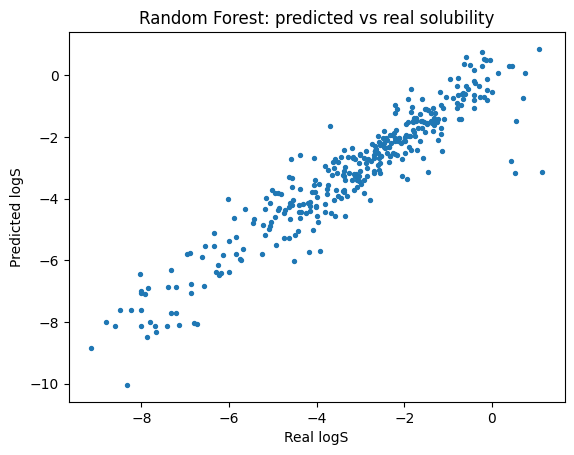

In [15]:
# See the predictions: draw predicted vs real logS.
import matplotlib.pyplot as plt
plt.scatter(y_test, pred, s=8)
plt.xlabel('Real logS')
plt.ylabel('Predicted logS')
plt.title('Random Forest: predicted vs real solubility')
plt.show()

**What you should see:** R² about 0.88 and RMSE about 0.73 — very close to Palmer's own numbers (0.89 / 0.69). In the picture, points near the diagonal line are good predictions.

**Tell Muse: 'Stage 3 done'** — or open Stage 4.


---
# STAGE 4 — Compare models + important descriptors
---

# Project 2 — Stage 4: Compare Models + Important Descriptors
**Goal:** train a simple linear model, compare it with Random Forest, and ask the forest which descriptors matter most. Palmer found lipophilicity (SlogP) was number 1. Watch for your LogP.

In [16]:
# Split into X (the descriptors) and y (the answer, logS), then 70/30 train/test.
from sklearn.model_selection import train_test_split
X = data.drop(columns=['logS'])
y = data['logS']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)
print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (789, 8)  Test: (339, 8)


In [17]:
# Train BOTH models.
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
rf = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1).fit(X_train, y_train)
lr = LinearRegression().fit(X_train, y_train)
print('Both trained.')

Both trained.


In [18]:
# Compare them.
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np
def grade(model, name):
    p = model.predict(X_test)
    print(name, '| R2:', round(r2_score(y_test, p), 3), '| RMSE:', round(float(np.sqrt(mean_squared_error(y_test, p))), 3))
grade(lr, 'Linear Regression')
grade(rf, 'Random Forest    ')

Linear Regression | R2: 0.779 | RMSE: 1.005
Random Forest     | R2: 0.882 | RMSE: 0.732


In [19]:
# Which descriptors does the Random Forest rely on most?
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print(imp.round(3))

LogP          0.810
MolWt         0.081
TPSA          0.041
HeavyAtoms    0.028
Rings         0.011
RotBonds      0.011
HBA           0.010
HBD           0.007
dtype: float64


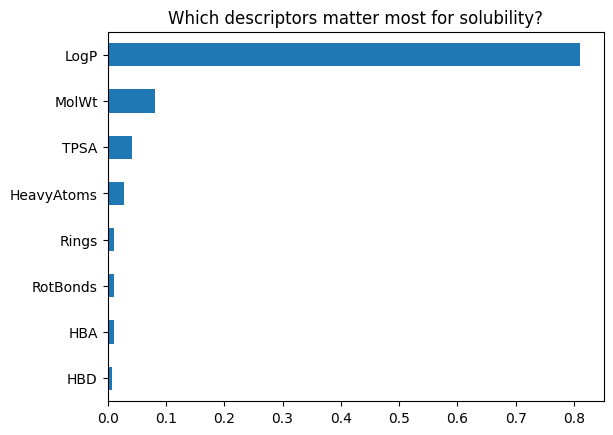

In [20]:
# The same, as a picture (this looks great on GitHub).
import matplotlib.pyplot as plt
imp.sort_values().plot(kind='barh')
plt.title('Which descriptors matter most for solubility?')
plt.show()


---
# STAGE 5 — Cross-validation + final results
---

# Project 2 — Stage 5: Cross-Validation + Final Results Table
**Goal:** check the Random Forest with 5-fold cross-validation (the honest test Palmer also used), then build the final results table for your report and GitHub.

In [21]:
# Cross-validation: the data is split 5 different ways and the model is graded 5 times.
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestRegressor
rf = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1)
scores = cross_val_score(rf, X, y, cv=5, scoring='r2')
print('5 fold R2 scores:', [round(s, 3) for s in scores])
print('Average R2:', round(scores.mean(), 3))

5 fold R2 scores: [np.float64(0.917), np.float64(0.898), np.float64(0.897), np.float64(0.879), np.float64(0.847)]
Average R2: 0.887


In [22]:
# Build the final results table.
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np
def rmse(a, b): return float(np.sqrt(mean_squared_error(a, b)))
rf.fit(X_train, y_train)
lr = LinearRegression().fit(X_train, y_train)
results = pd.DataFrame([
    {'Model': 'Linear Regression', 'R2 (test)': round(r2_score(y_test, lr.predict(X_test)), 3), 'RMSE (test)': round(rmse(y_test, lr.predict(X_test)), 3)},
    {'Model': 'Random Forest', 'R2 (test)': round(r2_score(y_test, rf.predict(X_test)), 3), 'RMSE (test)': round(rmse(y_test, rf.predict(X_test)), 3)},
])
results

,Model,R2 (test),RMSE (test)
0,Linear Regression,0.779,1.005
1,Random Forest,0.882,0.732


In [23]:
# Save the table as a CSV file (you will upload it to GitHub).
results.to_csv('solubility_model_comparison.csv', index=False)
print('Saved: solubility_model_comparison.csv')

Saved: solubility_model_comparison.csv


**What you should see:** cross-validation average R² about 0.89, matching your test score — the model is stable, not lucky.

## The finish line
1. In Colab: **File → Download → Download .ipynb** for the notebooks you ran (or make one combined notebook).
2. Create GitHub repo number 2: `solubility-prediction-rdkit`
3. Upload: notebook(s) + `solubility_model_comparison.csv`
4. Tell Muse **'Project 2 done'** and I will write your README, check the repo, and update your CV and portfolio — Project 2 goes right under Project 1.